Hotel Cancellation 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import GroupShuffleSplit, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import CategoricalNB
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)

### Retrieving data set from github repository

In [2]:
url = 'https://raw.githubusercontent.com/sascott9655/ADS-505-Hotel_Bookings_Project/main/hotel_bookings.csv'
df = pd.read_csv(url)
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,no,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,7/1/2015
1,Resort Hotel,no,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,7/1/2015
2,Resort Hotel,no,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,7/2/2015
3,Resort Hotel,no,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,7/2/2015
4,Resort Hotel,no,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,7/3/2015


### Sanity Check

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  str    
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [4]:
df["is_canceled"] = (df["is_canceled"] == "yes").astype(int) # yes/no -> 1/0 (this will matter for modeling later on!)
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print("\nMissing values:")
print(pd.DataFrame({"count": missing, "percent": (missing / len(df) * 100).round(1)}))
df.describe().T.round(2)


Missing values:
           count  percent
company   112593     94.3
agent      16340     13.7
country      488      0.4
children       4      0.0


,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.37,0.48,0.00,0.00,0.00,1.0,1.0
lead_time,119390.0,104.01,106.86,0.00,18.00,69.00,160.0,737.0
arrival_date_year,119390.0,2016.16,0.71,2015.00,2016.00,2016.00,2017.0,2017.0
arrival_date_week_number,119390.0,27.17,13.61,1.00,16.00,28.00,38.0,53.0
arrival_date_day_of_month,119390.0,15.80,8.78,1.00,8.00,16.00,23.0,31.0
stays_in_weekend_nights,119390.0,0.93,1.00,0.00,0.00,1.00,2.0,19.0
stays_in_week_nights,119390.0,2.50,1.91,0.00,1.00,2.00,3.0,50.0
adults,119390.0,1.86,0.58,0.00,2.00,2.00,2.0,55.0
children,119386.0,0.10,0.40,0.00,0.00,0.00,0.0,10.0
babies,119390.0,0.01,0.10,0.00,0.00,0.00,0.0,10.0


In [5]:
# How many duplicates are in the data?
duplicates = df.duplicated().sum()
print(f'There are {duplicates} duplicate rows in the dataset.')
df.shape

There are 31994 duplicate rows in the dataset.


(119390, 32)

In [6]:
# Are duplicates worth keeping?
dup_rows = df[df.duplicated(keep=False)]

segment_mix = (pd.DataFrame({
    'All Bookings (%)': df['market_segment'].value_counts(normalize=True),
    'Duplicate rows (%)': dup_rows['market_segment'].value_counts(normalize=True)
}) * 100).round(1).sort_values('Duplicate rows (%)', ascending=False)
segment_mix

,All Bookings (%),Duplicate rows (%)
market_segment,,
Groups,16.6,41.6
Offline TA/TO,20.3,30.4
Online TA,47.3,20.6
Corporate,4.4,3.7
Direct,10.6,3.5
Complementary,0.6,0.2
Aviation,0.2,0.0
Undefined,0.0,NaN


In [7]:
# Give every set of identical rows (e.g. the rooms in one group booking) a shared ID,
# used later so copies of the same booking stay together when splitting the data
df['booking_group'] = df.groupby(list(df.columns), dropna=False).ngroup()
df['booking_group'].nunique()

87396

In [8]:
#children impute missing value with zero(since they are so few missing values and most of the data shows that customers are not children 
#and/or with children)
impute_with_zero = (df['children'].isna() == True)
impute_with_zero = impute_with_zero[impute_with_zero == True]
df.loc[impute_with_zero.index, 'children'] = 0
df['children'].isna().sum()
 
df['country'] = df['country'].fillna('Unknown') #fill it with unknown as it shouldn't impact the data too much
df['country'].isna().sum()

df["has_company"] = df["company"].notna().astype(int)
df["has_company"]

df["has_agent"] = df["agent"].notna().astype(int) 
df["has_agent"]

df = df.drop(columns=["agent", "company"])

In [9]:
df.isna().sum() #no more missing data!!!

hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
meal                              0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
days_in_waiting_list              0
customer_type                     0
adr                               0
required_car_parking_spaces       0
total_of_special_requests   

In [10]:
df = df[(df["adults"] + df["children"] + df["babies"]) > 0] #gets rid of rows where there was no people tracked
df = df[df["adr"] >= 0]  # drop the one booking with a negative daily rate
df.shape

(119209, 33)

In [11]:
# Was there a deposit for the booking? If so, what kind?
df['deposit_type'].value_counts().to_frame()

,count
deposit_type,
No Deposit,104460
Non Refund,14587
Refundable,162


### Visualizations

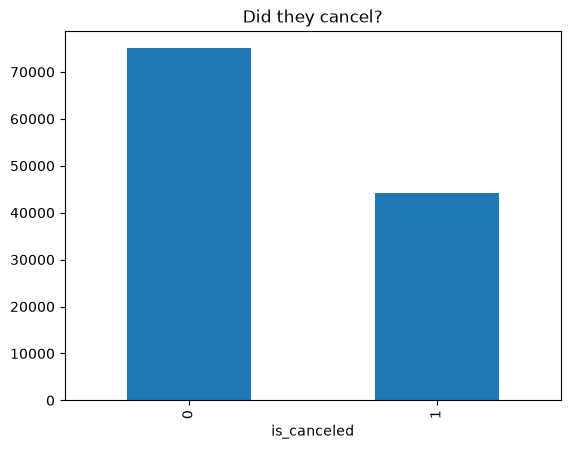

In [12]:
df['is_canceled'].value_counts().plot(kind='bar', title='Did they cancel?')
plt.show()

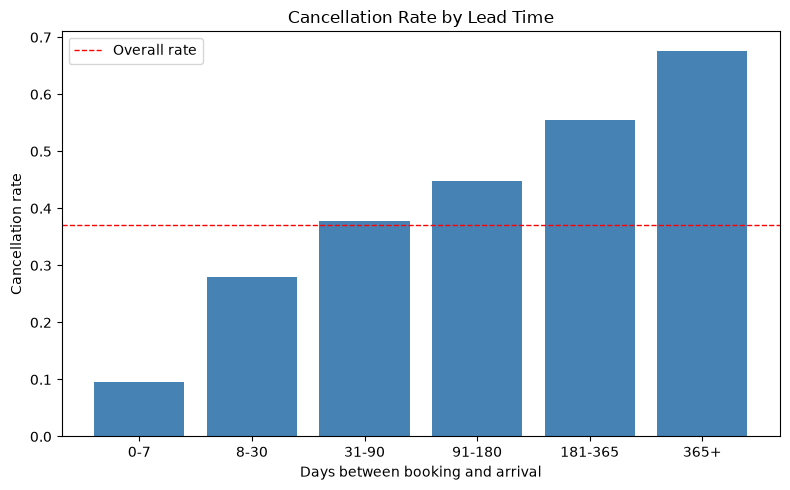

           count  cancel_rate
lead_time                    
0-7        19635        0.096
8-30       18945        0.279
31-90      29529        0.377
91-180     26420        0.447
181-365    21533        0.555
365+        3147        0.677


In [13]:
#Nice visual to show likelihood of cancellation based on how many days passed by.
lead_bins = pd.cut(df["lead_time"], bins=[-1, 7, 30, 90, 180, 365, 800],
                  labels=["0-7", "8-30", "31-90", "91-180", "181-365","365+"])
lead_rates = df.groupby(lead_bins, observed=True)["is_canceled"].agg(count="size", cancel_rate="mean")
plt.figure(figsize=(8, 5))
plt.bar(lead_rates.index.astype(str), lead_rates["cancel_rate"], color="steelblue")
plt.axhline(df["is_canceled"].mean(), color="red", linestyle="--", linewidth=1,label="Overall rate")
plt.title("Cancellation Rate by Lead Time")
plt.xlabel("Days between booking and arrival")
plt.ylabel("Cancellation rate")
plt.legend()
plt.tight_layout()
plt.show()
print(lead_rates.round(3))

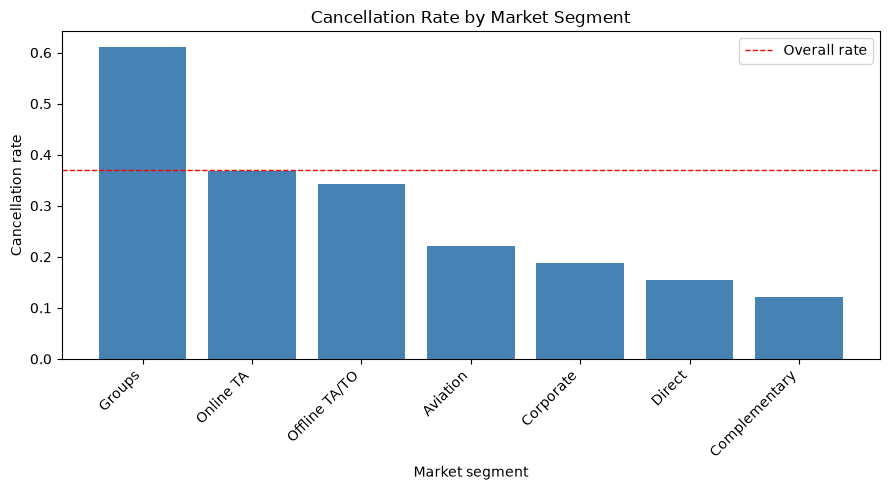

                count  cancel_rate
market_segment                    
Groups          19790        0.611
Online TA       56408        0.368
Offline TA/TO   24182        0.343
Aviation          235        0.221
Corporate        5282        0.188
Direct          12582        0.154
Complementary     728        0.122


In [14]:
seg_rates = (df.groupby("market_segment")["is_canceled"].agg(count="size",
            cancel_rate="mean").query("count > 100").sort_values("cancel_rate", ascending=False)) 
plt.figure(figsize=(9, 5))
plt.bar(seg_rates.index, seg_rates["cancel_rate"], color="steelblue")
plt.axhline(df["is_canceled"].mean(), color="red", linestyle="--", linewidth=1,label="Overall rate")
plt.title("Cancellation Rate by Market Segment")
plt.xlabel("Market segment")
plt.ylabel("Cancellation rate")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()
print(seg_rates.round(3))

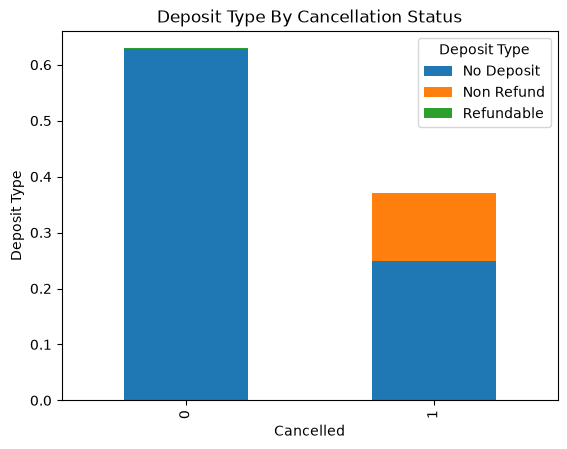

In [15]:
pd.crosstab(df['is_canceled'], df['deposit_type'], normalize=True).plot(kind='bar', stacked=True)
plt.title('Deposit Type By Cancellation Status')
plt.xlabel('Cancelled')
plt.ylabel('Deposit Type')
plt.legend(title='Deposit Type')
plt.show()

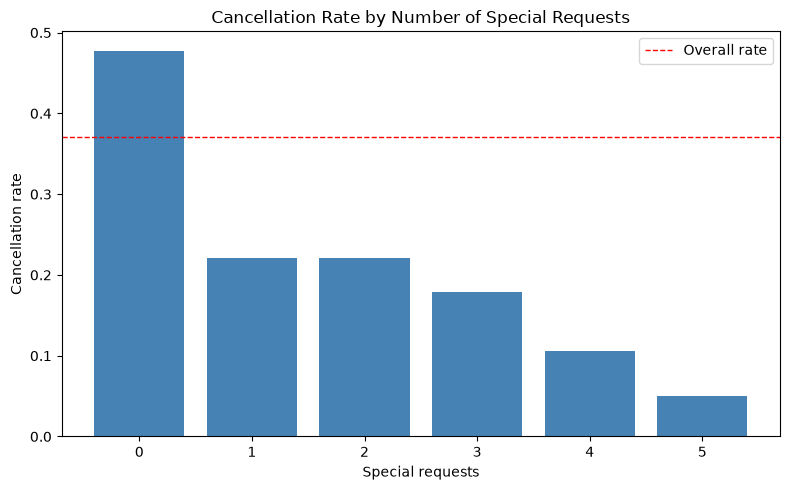

                           count  cancel_rate
total_of_special_requests                    
0                          70200        0.478
1                          33183        0.220
2                          12952        0.221
3                           2494        0.178
4                            340        0.106
5                             40        0.050


In [16]:
req_rates = df.groupby("total_of_special_requests")["is_canceled"].agg(count="size", cancel_rate="mean")
plt.figure(figsize=(8, 5))
plt.bar(req_rates.index.astype(str), req_rates["cancel_rate"],color="steelblue")
plt.axhline(df["is_canceled"].mean(), color="red", linestyle="--", linewidth=1,label="Overall rate")
plt.title("Cancellation Rate by Number of Special Requests")
plt.xlabel("Special requests")
plt.ylabel("Cancellation rate")
plt.legend()
plt.tight_layout()
plt.show()
print(req_rates.round(3))

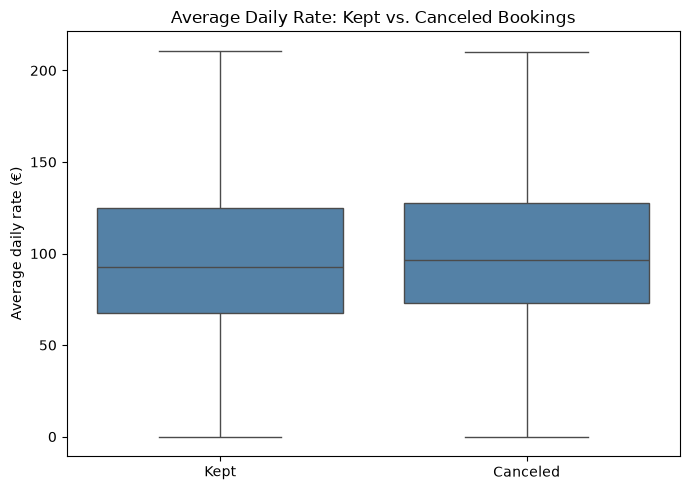

               mean   50%
is_canceled              
0            100.17  92.7
1            105.02  96.3


In [17]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="is_canceled", y="adr", showfliers=False,color="steelblue")
plt.xticks([0, 1], ["Kept", "Canceled"])
plt.title("Average Daily Rate: Kept vs. Canceled Bookings")
plt.xlabel("")
plt.ylabel("Average daily rate (€)")
plt.tight_layout()
plt.show()
print(df.groupby("is_canceled")["adr"].describe()[["mean", "50%"]].round(2))

### Feature Engineering

In [18]:
#dropping these two columns as the information they provide
#does not seem significant enough considering we have
#arrival_date_year and arrival_date_month
#dropping reservation_status and reservation_status_date because both of these columns allude to directly
#predicting the target variable is_canceled which we do not want a model with strong features that tell us
#the outcome based on these two features alone (not helpful for the business to improve hotel cancellation rate)
#dropping required_car_parking_spaces, booking_changes and days_in_waiting_list because they are likely
#recorded after the booking is made, so they would leak the outcome
df = df.drop(columns=['arrival_date_week_number', 'arrival_date_day_of_month', 'assigned_room_type',
                      'reservation_status', 'reservation_status_date',
                      'required_car_parking_spaces', 'booking_changes', 'days_in_waiting_list'])

df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,...,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,deposit_type,customer_type,adr,total_of_special_requests,booking_group,has_company,has_agent
0,Resort Hotel,0,342,2015,July,0,0,2,0.0,0,...,0,0,C,No Deposit,Transient,0.0,0,79092,0,0
1,Resort Hotel,0,737,2015,July,0,0,2,0.0,0,...,0,0,C,No Deposit,Transient,0.0,0,79419,0,0
2,Resort Hotel,0,7,2015,July,0,1,1,0.0,0,...,0,0,A,No Deposit,Transient,75.0,0,60910,0,0
3,Resort Hotel,0,13,2015,July,0,1,1,0.0,0,...,0,0,A,No Deposit,Transient,75.0,0,62795,0,1
4,Resort Hotel,0,14,2015,July,0,2,2,0.0,0,...,0,0,A,No Deposit,Transient,98.0,1,63017,0,1


In [19]:
df['length_of_stay'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df[['stays_in_weekend_nights', 'stays_in_week_nights', 'length_of_stay']].head(30)

,stays_in_weekend_nights,stays_in_week_nights,length_of_stay
0,0,0,0
1,0,0,0
2,0,1,1
3,0,1,1
4,0,2,2
5,0,2,2
6,0,2,2
7,0,2,2
8,0,3,3
9,0,3,3


In [20]:
#for features stays_in_weekend_nights and stays_in_week_nights we can feature engineer these two columns into 
#one where it is a binary feature on whether they stay the weekend or not
df['stays_in_weekend_nights'].value_counts()
weekend_nights_yes = df['stays_in_weekend_nights'] > 0
weekend_nights_yes = weekend_nights_yes[weekend_nights_yes == True]
df.loc[weekend_nights_yes.index, 'stays_in_weekend_nights'] = 1
df['stays_in_weekend_nights'].value_counts()

#drop stay_in_week_nights column as it is no longer needed
df = df.drop(columns=['stays_in_week_nights'])
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,stays_in_weekend_nights,adults,children,babies,meal,...,previous_bookings_not_canceled,reserved_room_type,deposit_type,customer_type,adr,total_of_special_requests,booking_group,has_company,has_agent,length_of_stay
0,Resort Hotel,0,342,2015,July,0,2,0.0,0,BB,...,0,C,No Deposit,Transient,0.0,0,79092,0,0,0
1,Resort Hotel,0,737,2015,July,0,2,0.0,0,BB,...,0,C,No Deposit,Transient,0.0,0,79419,0,0,0
2,Resort Hotel,0,7,2015,July,0,1,0.0,0,BB,...,0,A,No Deposit,Transient,75.0,0,60910,0,0,1
3,Resort Hotel,0,13,2015,July,0,1,0.0,0,BB,...,0,A,No Deposit,Transient,75.0,0,62795,0,1,1
4,Resort Hotel,0,14,2015,July,0,2,0.0,0,BB,...,0,A,No Deposit,Transient,98.0,1,63017,0,1,2


In [21]:
#for features children and babies consider combining them into one group since individual they act the same
#(running this code multiple times will change results
df['children'] = df['children'] + df['babies']
df['children'] = df['children'].astype('int')

df = df.drop(columns=['babies'])
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,stays_in_weekend_nights,adults,children,meal,country,...,previous_bookings_not_canceled,reserved_room_type,deposit_type,customer_type,adr,total_of_special_requests,booking_group,has_company,has_agent,length_of_stay
0,Resort Hotel,0,342,2015,July,0,2,0,BB,PRT,...,0,C,No Deposit,Transient,0.0,0,79092,0,0,0
1,Resort Hotel,0,737,2015,July,0,2,0,BB,PRT,...,0,C,No Deposit,Transient,0.0,0,79419,0,0,0
2,Resort Hotel,0,7,2015,July,0,1,0,BB,GBR,...,0,A,No Deposit,Transient,75.0,0,60910,0,0,1
3,Resort Hotel,0,13,2015,July,0,1,0,BB,GBR,...,0,A,No Deposit,Transient,75.0,0,62795,0,1,1
4,Resort Hotel,0,14,2015,July,0,2,0,BB,GBR,...,0,A,No Deposit,Transient,98.0,1,63017,0,1,2


In [22]:
top_countries = df["country"].value_counts().nlargest(10).index
#I like the idea of having an other column for countries that do not appear in the data set often
df["country"] = df["country"].where(df["country"].isin(top_countries), "Other")
df.info()

<class 'pandas.DataFrame'>
Index: 119209 entries, 0 to 119389
Data columns (total 24 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119209 non-null  str    
 1   is_canceled                     119209 non-null  int64  
 2   lead_time                       119209 non-null  int64  
 3   arrival_date_year               119209 non-null  int64  
 4   arrival_date_month              119209 non-null  str    
 5   stays_in_weekend_nights         119209 non-null  int64  
 6   adults                          119209 non-null  int64  
 7   children                        119209 non-null  int64  
 8   meal                            119209 non-null  str    
 9   country                         119209 non-null  str    
 10  market_segment                  119209 non-null  str    
 11  distribution_channel            119209 non-null  str    
 12  is_repeated_guest               

Columns like meal, country, reserved_room_type, customer_type, deposit_type  need to be one hot-encoded!

In [23]:
#leave hotel variable out because we will split the data on it
cat_cols = ['arrival_date_month', 'meal', 'country', 'reserved_room_type', 'customer_type', 'deposit_type',
            'market_segment', 'distribution_channel']
cat_data = df[cat_cols]
cat_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
cat_feat = pd.DataFrame(cat_encoder.fit_transform(cat_data),
                        columns=cat_encoder.get_feature_names_out(cat_cols),
                        index=cat_data.index)
cat_feat
df = pd.concat([df, cat_feat], axis=1)
df = df.drop(columns=cat_cols)
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,stays_in_weekend_nights,adults,children,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,...,market_segment_Direct,market_segment_Groups,market_segment_Offline TA/TO,market_segment_Online TA,market_segment_Undefined,distribution_channel_Corporate,distribution_channel_Direct,distribution_channel_GDS,distribution_channel_TA/TO,distribution_channel_Undefined
0,Resort Hotel,0,342,2015,0,2,0,0,0,0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,Resort Hotel,0,737,2015,0,2,0,0,0,0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,Resort Hotel,0,7,2015,0,1,0,0,0,0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,Resort Hotel,0,13,2015,0,1,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,Resort Hotel,0,14,2015,0,2,0,0,0,0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


In [24]:
# Split into one table per hotel so each gets its own model
city_hotel = df[df["hotel"] == "City Hotel"].copy()
resort_hotel = df[df["hotel"] == "Resort Hotel"].copy()
print(city_hotel["is_canceled"].mean()) 
print(resort_hotel["is_canceled"].mean())

0.4178593534858457
0.2776806672326824


City hotel a little more likely to be canceled than resort hotel. 

In [25]:
df.shape

(119209, 73)

In [26]:
# Features: everything except the answer, the hotel name and the booking group ID
X_city = city_hotel.drop(columns=['is_canceled', 'hotel', 'booking_group'])
X_resort = resort_hotel.drop(columns=['is_canceled', 'hotel', 'booking_group'])

# Answer: did the booking cancel? (1 = yes, 0 = no)
y_city = city_hotel['is_canceled']
y_resort = resort_hotel['is_canceled']

# Booking group IDs, used only to keep copies of the same booking together in the split
groups_city = city_hotel['booking_group']
groups_resort = resort_hotel['booking_group']

In [27]:
# Shared split for every model: 60% train / 20% validation / 20% test per hotel.
# GroupShuffleSplit keeps all copies of a group booking on the same side, so no model
# is scored on an exact copy of a row it trained on.
def group_split(X, y, groups, seed=11):
    outer = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=seed)
    train_valid_idx, test_idx = next(outer.split(X, y, groups))

    inner = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=seed)
    train_idx, valid_idx = next(inner.split(X.iloc[train_valid_idx], y.iloc[train_valid_idx],
                                            groups.iloc[train_valid_idx]))
    train_idx, valid_idx = train_valid_idx[train_idx], train_valid_idx[valid_idx]

    return (X.iloc[train_idx], X.iloc[valid_idx], X.iloc[test_idx],
            y.iloc[train_idx], y.iloc[valid_idx], y.iloc[test_idx])


X_city_train, X_city_valid, X_city_test, y_city_train, y_city_valid, y_city_test = group_split(
    X_city, y_city, groups_city)
X_resort_train, X_resort_valid, X_resort_test, y_resort_train, y_resort_valid, y_resort_test = group_split(
    X_resort, y_resort, groups_resort)

print('City   | Train:', len(X_city_train), '| Valid:', len(X_city_valid), '| Test:', len(X_city_test),
      '| Cancel rates:', round(y_city_train.mean(), 3), round(y_city_valid.mean(), 3), round(y_city_test.mean(), 3))
print('Resort | Train:', len(X_resort_train), '| Valid:', len(X_resort_valid), '| Test:', len(X_resort_test),
      '| Cancel rates:', round(y_resort_train.mean(), 3), round(y_resort_valid.mean(), 3), round(y_resort_test.mean(), 3))

City   | Train: 47293 | Valid: 15448 | Test: 16422 | Cancel rates: 0.417 0.413 0.426
Resort | Train: 24079 | Valid: 7957 | Test: 8010 | Cancel rates: 0.275 0.279 0.285


In [28]:
# Every model adds its validation scores to `results` so all models land in one comparison table
results = []


def evaluate(model_name, hotel, y_true, prob, threshold=0.5):
    """Score validation predictions at a given cutoff and return one row for the results table."""
    pred = (prob >= threshold).astype(int)
    return {'Model': model_name, 'Hotel': hotel, 'Threshold': threshold,
            'Accuracy': accuracy_score(y_true, pred),
            'Precision': precision_score(y_true, pred),
            'Recall': recall_score(y_true, pred),
            'F1': f1_score(y_true, pred),
            'ROC AUC': roc_auc_score(y_true, prob)}

In [29]:
# Logistic regression for the city hotel
# Scale Features
city_scaler = StandardScaler().fit(X_city_train)

# Fit the City model
city_log = LogisticRegression(max_iter=1000)
city_log.fit(city_scaler.transform(X_city_train), y_city_train)

# Predict on the City validation set
city_valid_pred = city_log.predict(city_scaler.transform(X_city_valid))
city_valid_prob = city_log.predict_proba(city_scaler.transform(X_city_valid))[:, 1]

print('Baseline (predict no one cancels): ', round(1 - y_city_valid.mean(), 3))
print('Accuracy: ', round(accuracy_score(y_city_valid, city_valid_pred), 3))
print('Precision: ', round(precision_score(y_city_valid, city_valid_pred), 3))
print('Recall: ', round(recall_score(y_city_valid, city_valid_pred), 3))
print('ROC AUC: ', round(roc_auc_score(y_city_valid, city_valid_prob), 3))
results.append(evaluate('Logistic Regression', 'City', y_city_valid, city_valid_prob))
confusion_matrix(y_city_valid, city_valid_pred)

Baseline (predict no one cancels):  0.587
Accuracy:  0.797
Precision:  0.819
Recall:  0.652
ROC AUC:  0.871


array([[8153,  920],
       [2221, 4154]])

In [30]:
# Logistic regression for the resort hotel
# Scale features
resort_scaler = StandardScaler().fit(X_resort_train)

# Fit the Resort model
resort_log = LogisticRegression(max_iter=1000)
resort_log.fit(resort_scaler.transform(X_resort_train), y_resort_train)

# Predict on the Resort validation set
resort_valid_pred = resort_log.predict(resort_scaler.transform(X_resort_valid))
resort_valid_prob = resort_log.predict_proba(resort_scaler.transform(X_resort_valid))[:, 1]

print('Baseline (predict no one cancels): ', round(1 - y_resort_valid.mean(), 3))
print('Accuracy: ', round(accuracy_score(y_resort_valid, resort_valid_pred), 3))
print('Precision: ', round(precision_score(y_resort_valid, resort_valid_pred), 3))
print('Recall: ', round(recall_score(y_resort_valid, resort_valid_pred), 3))
print('ROC AUC: ', round(roc_auc_score(y_resort_valid, resort_valid_prob), 3))
results.append(evaluate('Logistic Regression', 'Resort', y_resort_valid, resort_valid_prob))
confusion_matrix(y_resort_valid, resort_valid_pred)

Baseline (predict no one cancels):  0.721
Accuracy:  0.809
Precision:  0.724
Recall:  0.51
ROC AUC:  0.865


array([[5306,  431],
       [1088, 1132]])

In [31]:
# Precision and recall at different cutoffs (validation set only)
city_thresholds = pd.DataFrame([
    {'Threshold': t,
     'Precision': round(precision_score(y_city_valid, city_valid_prob >= t), 3),
     'Recall': round(recall_score(y_city_valid, city_valid_prob >= t), 3),
     'Bookings flagged': (city_valid_prob >= t).sum()}
    for t in [0.5, 0.6, 0.7, 0.8]
])
city_thresholds


,Threshold,Precision,Recall,Bookings flagged
0,0.5,0.819,0.652,5074
1,0.6,0.883,0.568,4101
2,0.7,0.939,0.486,3298
3,0.8,0.980,0.442,2876


In [32]:
# Same 90% precision target for both hotels: a wrongly flagged booking is costly at either one
city_target, resort_target = 0.90, 0.90


def pick_threshold(y_valid, valid_prob, target):
    """Return the lowest cutoff that reaches the precision target on validation."""
    for t in np.arange(0.30, 0.96, 0.01):
        if precision_score(y_valid, valid_prob >= t) >= target:
            return round(t, 2)


city_threshold = pick_threshold(y_city_valid, city_valid_prob, city_target)
resort_threshold = pick_threshold(y_resort_valid, resort_valid_prob, resort_target)

results.append(evaluate('Logistic Regression (tuned cutoff)', 'City', y_city_valid, city_valid_prob, city_threshold))
results.append(evaluate('Logistic Regression (tuned cutoff)', 'Resort', y_resort_valid, resort_valid_prob, resort_threshold))
pd.DataFrame(results).round(3)

,Model,Hotel,Threshold,Accuracy,Precision,Recall,F1,ROC AUC
0,Logistic Regression,City,0.50,0.797,0.819,0.652,0.726,0.871
1,Logistic Regression,Resort,0.50,0.809,0.724,0.510,0.598,0.865
2,Logistic Regression (tuned cutoff),City,0.63,0.789,0.903,0.546,0.681,0.871
3,Logistic Regression (tuned cutoff),Resort,0.83,0.777,0.902,0.224,0.359,0.865


# Logistic Regression Takeaway
For both City and Resort hotels a False Positive, a reservation flagged as a cancellation when they did not end up canceling, is more costly than False Negative. What that means for modeling is we want to favor Precision over Recall, the reason being is if a hotel overbooks they risk a bad review, having to pay for customers stay plus travel expenses, bad review etc. On the other hand if a hotel misses a cancellation worst case they miss out on the adr(average daily rate) on their establishment... less costly than flagging somekone as cancelled and they not cancel.

The two hotels don't behave the same way, though. At the City Hotel, a cutoff of 0.63 reaches 90% precision while still catching about 55% of cancellations, so the model is reliable enough to support overbooking decisions. The Resort Hotel needs a cutoff of 0.83 to reach that same 90% precision, and at that point it only catches about 22% of cancellations. The Resort model still ranks bookings well (AUC 0.865), but very few of its bookings get high-confidence predictions, which suggests Resort cancellations are harder to see coming from booking details alone, likely because they're driven more by individual leisure travelers changing plans than by group or agency bookings. We still hold the Resort to the same 90% target, because wrongly flagging a booking is just as costly there. The low recall is the finding: the Resort model should only act on the small number of bookings it is very confident about.


### Naive Bayes (Brandon)

In [33]:
# Paste the Naive Bayes model here using the shared split above
# (X_city_train / X_city_valid / y_city_train / y_city_valid and the resort versions).
# Add validation scores with:
# results.append(evaluate('Naive Bayes', 'City', y_city_valid, nb_city_valid_prob))

### Neural Network (Samuel)

In [34]:
# Paste the neural network model here using the shared split above
# (X_city_train / X_city_valid / y_city_train / y_city_valid and the resort versions).
# Features are already one-hot encoded, so only scaling is needed.
# Add validation scores with:
# results.append(evaluate('Neural Network', 'City', y_city_valid, nn_city_valid_prob))

### Model Comparison (Validation Set)

In [35]:
# All models side by side on the same validation rows
pd.DataFrame(results).sort_values(['Hotel', 'Precision'], ascending=[True, False]).round(3)

,Model,Hotel,Threshold,Accuracy,Precision,Recall,F1,ROC AUC
2,Logistic Regression (tuned cutoff),City,0.63,0.789,0.903,0.546,0.681,0.871
0,Logistic Regression,City,0.50,0.797,0.819,0.652,0.726,0.871
3,Logistic Regression (tuned cutoff),Resort,0.83,0.777,0.902,0.224,0.359,0.865
1,Logistic Regression,Resort,0.50,0.809,0.724,0.510,0.598,0.865


### Final Model on Test Set

In [36]:
# Run only the chosen model on X_city_test / X_resort_test once, at its chosen cutoff